# Project

## Imports

In [1]:
!pip install -q segmentation-models-pytorch pytorch-msssim albumentations lightning torchmetrics onnxscript kornia

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 556.4 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.6/853.6 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 32.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 714.8/714.8 kB 40.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 47.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 47.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.6/17.6 MB 59.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.8/166.8 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.3/857.3 kB 53.1 MB/s eta 0:00:00


In [2]:
import os
import glob
import kagglehub
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import albumentations as A
import segmentation_models_pytorch as smp
import lightning as pl
import torch.nn.functional as F
import torchvision.transforms.functional as TF
import onnx
import kornia
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from albumentations.pytorch import ToTensorV2
from google.colab import drive
from pytorch_msssim import ssim
from torchmetrics.image import PeakSignalNoiseRatio, StructuralSimilarityIndexMeasure
from lightning.pytorch.callbacks import ModelCheckpoint, EarlyStopping, LearningRateMonitor
from lightning.pytorch.loggers import CSVLogger

In [3]:
drive.mount("/content/drive")
DRIVE_PATH = "/content/drive/MyDrive/Colab Notebooks/Deep Learning/Final_Project/"
os.makedirs(DRIVE_PATH, exist_ok=True)

# NOTE: add Kaggle API token to the Google Colab Secrets
# KAGGLE_API_TOKEN = userdata.get('KAGGLE_API_TOKEN')

Mounted at /content/drive


## Dataset Preparation

In [7]:
DATASET_SLUG = "soumikrakshit/lol-dataset"
DOWNLOAD_DIR = "/content/dataset"

# !kaggle datasets download -d {DATASET_SLUG} -p {DOWNLOAD_DIR} --unzip
kagglehub.dataset_download(DATASET_SLUG, output_dir="/content/", force_download=True)

# if needed
!cp -r /kaggle/input/lol-dataset/lol_dataset /content/
!mv /content/lol_dataset /content/dataset

print(f"Dataset downloaded and extracted to: {DOWNLOAD_DIR}")

Using Colab cache for faster access to the 'lol-dataset' dataset.
Dataset downloaded and extracted to: /content/dataset


In [22]:
TRAIN_LOW_DIR  = os.path.join(DOWNLOAD_DIR, "our485", "low")
TRAIN_HIGH_DIR = os.path.join(DOWNLOAD_DIR, "our485", "high")
EVAL_LOW_DIR   = os.path.join(DOWNLOAD_DIR, "eval15", "low")
EVAL_HIGH_DIR  = os.path.join(DOWNLOAD_DIR, "eval15", "high")

In [ ]:
class LOLDataset(Dataset):
    IMG_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp"}

    def __init__(self, low_dir: str, high_dir: str,
                 input_transform=None, spatial_transform=None):
        super().__init__()
        self.low_dir          = low_dir
        self.high_dir         = high_dir
        self.input_transform  = input_transform
        self.spatial_transform = spatial_transform

        low_files  = {f for f in os.listdir(low_dir) if os.path.splitext(f)[1].lower() in self.IMG_EXTENSIONS}
        high_files = {f for f in os.listdir(high_dir) if os.path.splitext(f)[1].lower() in self.IMG_EXTENSIONS}
        self.filenames = sorted(low_files & high_files)
        assert len(self.filenames) > 0, f"No matching pairs found in {low_dir} / {high_dir}"

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        fname = self.filenames[idx]
        low  = np.array(Image.open(os.path.join(self.low_dir,  fname)).convert("RGB"))
        high = np.array(Image.open(os.path.join(self.high_dir, fname)).convert("RGB"))

        if self.spatial_transform:
            aug  = self.spatial_transform(image=low, mask=high)
            low  = aug["image"]
            high = aug["mask"]

        high = torch.from_numpy(high).permute(2, 0, 1).float() / 255.0

        if self.input_transform:
            low = self.input_transform(image=low)["image"]
        else:
            low = torch.from_numpy(low).permute(2, 0, 1).float() / 255.0

        return {"low": low, "high": high, "fname": fname}

In [23]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)
IMG_SIZE      = 512
BATCH_SIZE    = 4
NUM_WORKERS   = 2

In [ ]:
train_spatial = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.RandomRotate90(p=0.3),
], additional_targets={"mask": "image"})

val_spatial = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
], additional_targets={"mask": "image"})

# Input transforms ensure pixels are [0, 1]
train_input = A.Compose([A.ToFloat(max_value=255.0), ToTensorV2()])
val_input = A.Compose([A.ToFloat(max_value=255.0), ToTensorV2()])

train_dataset = LOLDataset(TRAIN_LOW_DIR, TRAIN_HIGH_DIR, input_transform=train_input, spatial_transform=train_spatial)
val_dataset   = LOLDataset(EVAL_LOW_DIR,  EVAL_HIGH_DIR,  input_transform=val_input,   spatial_transform=val_spatial)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=1, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

print(f"Train pairs  : {len(train_dataset)}")
print(f"Val   pairs  : {len(val_dataset)}")
print(f"Train batches: {len(train_loader)}")

Train pairs  : 485
Val   pairs  : 15
Train batches: 122


## Model

In [ ]:
# ## Model — U-Net with pretrained MobileNetV2 encoder
#
# `segmentation_models_pytorch` gives us a full U-Net with:
# - **Encoder:** MobileNetV2 pretrained on ImageNet (transfer learning)
# - **Decoder:** U-Net decoder with skip connections
# - **Head:** 3-channel sigmoid output → pixel values in [0, 1]
#
# Why MobileNetV2 over ResNet-18?
# - Comparable accuracy, ~3× fewer parameters
# - Much faster on CPU at inference time (important for the VPS deployment later)

def build_model() -> smp.Unet:
    model = smp.Unet(
        encoder_name    = "mobilenet_v2",
        encoder_weights = "imagenet",
        in_channels     = 3,
        classes         = 1,
        activation      = "sigmoid",
        decoder_use_batchnorm = True,
    )
    return model

model = build_model()

# Quick sanity check
device     = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model      = model.to(device)
dummy      = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=device)
out        = model(dummy)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Device          : {device}")
print(f"Input shape     : {tuple(dummy.shape)}")
print(f"Output shape    : {tuple(out.shape)}")
print(f"Total params    : {total_params:,}")
print(f"Trainable params: {trainable_params:,}")

del model

Device          : cpu
Input shape     : (1, 3, 512, 512)
Output shape    : (1, 1, 512, 512)
Total params    : 6,628,945
Trainable params: 6,628,945


## Training

In [ ]:
class HybridLoss(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.l1 = torch.nn.L1Loss()

    def forward(self, pred: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        loss_l1 = self.l1(pred, target)
        # RGB hence evaluate the final reconstructed RGB image
        loss_ssim = 1.0 - ssim(pred, target, data_range=1.0, size_average=True)
        return loss_l1 + (0.5 * loss_ssim)

In [ ]:
class LumenNet(pl.LightningModule):
    def __init__(self, lr: float = 1e-4):
        super().__init__()
        self.save_hyperparameters()
        self.model = build_model()
        self.loss  = HybridLoss()

        self.train_psnr = PeakSignalNoiseRatio(data_range=1.0)
        self.val_psnr   = PeakSignalNoiseRatio(data_range=1.0)
        self.val_ssim   = StructuralSimilarityIndexMeasure(data_range=1.0)

    def forward(self, x):
        # x is [B, 3, H, W] in [0, 1]

        # convert to LAB Space (L is [0, 100], A and B are ~[-128, 128])
        lab = kornia.color.rgb_to_lab(x)
        l_chan = lab[:, 0:1, :, :]
        a_chan = lab[:, 1:2, :, :]
        b_chan = lab[:, 2:3, :, :]

        # normalize L to [0, 1]
        l_norm = l_chan / 100.0

        # transfer learning prep: the network expects 3 channels. Duplicate L.
        l_3 = l_norm.repeat(1, 3, 1, 1)

        # apply ImageNet normalization strictly for the encoder
        mean = torch.tensor(IMAGENET_MEAN, device=x.device).view(1, 3, 1, 1)
        std = torch.tensor(IMAGENET_STD, device=x.device).view(1, 3, 1, 1)
        l_3_in = (l_3 - mean) / std

        # predict the new Lightness channel [0, 1] and scale back to [0, 100]
        l_new_norm = self.model(l_3_in)
        l_new = l_new_norm * 100.0

        # chromaticity preserver: calculate the multiplication ratio
        ratio = (l_new + 1e-5) / (l_chan + 1e-5)

        # prevent the ratio from exceeding 3x to stop shadow noise amplification
        ratio = torch.clamp(ratio, 0.0, 3.0)

        a_new = a_chan * ratio
        b_new = b_chan * ratio

        # enforce Kornia's valid LAB color boundaries
        a_new = torch.clamp(a_new, -128.0, 128.0)
        b_new = torch.clamp(b_new, -128.0, 128.0)

        # recombine and convert back to RGB
        lab_new = torch.cat([l_new, a_new, b_new], dim=1)
        enhanced_rgb = kornia.color.lab_to_rgb(lab_new)

        return torch.clamp(enhanced_rgb, 0.0, 1.0)

    def _shared_step(self, batch):
        low, high = batch["low"], batch["high"]
        pred      = self(low)
        loss      = self.loss(pred, high)
        return loss, pred, high

    def training_step(self, batch, batch_idx):
        loss, pred, high = self._shared_step(batch)
        self.train_psnr(pred, high)
        self.log("train/loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        self.log("train/psnr", self.train_psnr, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        loss, pred, high = self._shared_step(batch)
        self.val_psnr(pred, high)
        self.val_ssim(pred, high)
        self.log("val/loss", loss, on_epoch=True, prog_bar=True)
        self.log("val/psnr", self.val_psnr, on_epoch=True, prog_bar=True)
        self.log("val/ssim", self.val_ssim, on_epoch=True, prog_bar=True)

    def configure_optimizers(self):
        optimizer = torch.optim.Adam(self.parameters(), lr=self.hparams.lr, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=50, eta_min=1e-6
        )
        return {"optimizer": optimizer, "lr_scheduler": scheduler}

In [ ]:
# restore models and logs from drive
if os.path.exists(os.path.join(DRIVE_PATH, "checkpoints")):
    print("Restoring saved checkpoints from Drive...")
    os.system(f"cp -ru '{DRIVE_PATH}checkpoints' '/content/'")

if os.path.exists(os.path.join(DRIVE_PATH, "logs")):
    print("Restoring logs from Drive...")
    os.system(f"cp -ru '{DRIVE_PATH}logs' '/content/'")

In [ ]:
CHECKPOINT_DIR = "/content/checkpoints"

checkpoint_cb = ModelCheckpoint(
    dirpath   = CHECKPOINT_DIR,
    filename  = "lumennet-{epoch:02d}-psnr{val/psnr:.2f}",
    monitor   = "val/psnr",
    mode      = "max",
    save_top_k= 3,
    save_last = True,
)

early_stop_cb = EarlyStopping(monitor="val/psnr", patience=10, mode="max")
lr_monitor = LearningRateMonitor(logging_interval="epoch")

In [ ]:
lumennet = LumenNet(lr=1e-4)
logger = CSVLogger("logs", name="lumennet_tl")

trainer = pl.Trainer(
    max_epochs=50,
    accelerator="auto",
    precision="32-true",
    logger=logger,
    callbacks=[checkpoint_cb, early_stop_cb, lr_monitor],
    log_every_n_steps=10,
    enable_progress_bar=True,
)

resume_ckpt = None
if os.path.exists(CHECKPOINT_DIR):
    ckpt_files = glob.glob(os.path.join(CHECKPOINT_DIR, "*.ckpt"))
    if ckpt_files:
        resume_ckpt = max(ckpt_files, key=os.path.getctime)
        print(f"Resuming training from checkpoint: {resume_ckpt}")

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [ ]:
trainer.fit(lumennet, train_loader, val_loader, ckpt_path=resume_ckpt)

os.system(f"cp -ru /content/checkpoints '{DRIVE_PATH}'")
os.system(f"cp -ru /content/logs '{DRIVE_PATH}'")
print("\nArtifacts backed up to Google Drive")

INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name       ┃ Type                             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model      │ Unet                             │  6.6 M │ train │     0 │
│ 1 │ loss       │ HybridLoss                       │      0 │ train │     0 │
│ 2 │ train_psnr │ PeakSignalNoiseRatio             │      0 │ train │     0 │
│ 3 │ val_psnr   │ PeakSignalNoiseRatio             │      0 │ train │     0 │
│ 4 │ val_ssim   │ StructuralSimilarityIndexMeasure │      0 │ train │     0 │
└───┴────────────┴──────────────────────────────────┴────────┴───────┴───────┘

Trainable params: 6.6 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 6.6 M                                                                                                
Total estimated model params size (MB): 26                                                                         
Modules in train mode: 289                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()


Artifacts backed up to Google Drive


In [ ]:
final_ckpt_path = checkpoint_cb.best_model_path if checkpoint_cb.best_model_path else resume_ckpt
best_score = checkpoint_cb.best_model_score

print(f"\nBest checkpoint: {final_ckpt_path}")
if best_score is not None:
    print(f"Best val PSNR  : {best_score:.3f} dB")
else:
    print("Best val PSNR  : N/A (Resumed from completed state)")


Best checkpoint: /content/checkpoints/lumennet-epoch=16-psnrval/psnr=19.16.ckpt
Best val PSNR  : 19.159 dB


In [ ]:
print("Loading best checkpoint for ONNX export...")
best_model = LumenNet.load_from_checkpoint(final_ckpt_path, map_location=torch.device('cpu'))
best_model.to('cpu')
best_model.eval()

# Dummy input in [0, 1]
dummy_input = torch.rand(1, 3, 512, 512, device='cpu')

onnx_file_path = "lumennet_best.onnx"
temp_onnx = "temp_split.onnx"

import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    torch.onnx.export(
        best_model,
        dummy_input,
        temp_onnx,
        export_params=True,
        opset_version=18,
        do_constant_folding=True,
        input_names=['input'],
        output_names=['output'],
        dynamic_axes={
            'input':  {0: 'batch_size', 2: 'height', 3: 'width'},
            'output': {0: 'batch_size', 2: 'height', 3: 'width'}
        }
    )

model_proto = onnx.load(temp_onnx)
!rm "/content/{temp_onnx}"
!rm "/content/{temp_onnx}.data"
onnx.save_model(model_proto, onnx_file_path, save_as_external_data=False)

if os.path.exists(onnx_file_path):
    os.system(f"cp -u {onnx_file_path} '{DRIVE_PATH}'")
    print(f"ONNX export complete, files securely saved to {DRIVE_PATH}")

Loading best checkpoint for ONNX export...


W0513 01:36:59.269000 27012 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0513 01:36:59.271000 27012 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'rois' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0513 01:36:59.273000 27012 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0). Treating as an Input.
W0513 01:36:59.275000 27012 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'boxes' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0). Treating as an Input.


[torch.onnx] Obtain model graph for `LumenNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `LumenNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...
[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
ONNX export complete, files securely saved to /content/drive/MyDrive/Colab Notebooks/Deep Learning/Final_Project/


## Results

In [ ]:
sns.set_theme(context="paper", style="whitegrid", palette="colorblind", font_scale=1.5)

In [ ]:
log_path = "/content/logs/lumennet_tl/version_0/metrics.csv"

if os.path.exists(log_path):
    df = pd.read_csv(log_path)

    # group by epoch to merge train and val rows
    df_epoch = df.groupby('epoch').mean().reset_index()
else:
    print(f"Log file not found at {log_path}. Ensure training completed successfully.")
    df_epoch = pd.DataFrame()

In [ ]:
# Change 'version_0' if you are on a later run
log_path = "/content/logs/lumennet_tl/version_0/metrics.csv"

df = pd.read_csv(log_path)

# group by epoch, mean them, and forward-fill missing values
df_clean = df.groupby('epoch').mean().ffill().bfill().reset_index()

# extract specific columns of interest
cols = ['epoch', 'train/loss', 'val/loss', 'train/psnr', 'val/psnr', 'val/ssim']
# filter only columns that actually exist in the dataframe to avoid errors
cols = [c for c in cols if c in df_clean.columns]

last_epoch = df_clean.iloc[-1:]
best_psnr_row = df_clean.loc[df_clean['val/psnr'].idxmax()].to_frame().T

In [ ]:
print("Last Epoch Metrics:")
last_epoch[cols].round(4)

Last Epoch Metrics:


,epoch,train/loss,val/loss,train/psnr,val/psnr,val/ssim
26,26.0,0.1654,0.2124,20.1785,18.196,0.7629


In [ ]:
print("\nBest Epoch (Max Val PSNR):")
best_psnr_row[cols].round(4)


Best Epoch (Max Val PSNR):


,epoch,train/loss,val/loss,train/psnr,val/psnr,val/ssim
16,16.0,0.1793,0.1984,19.3773,19.1586,0.7672


In [5]:
os.makedirs("/content/plots/", exist_ok=True)

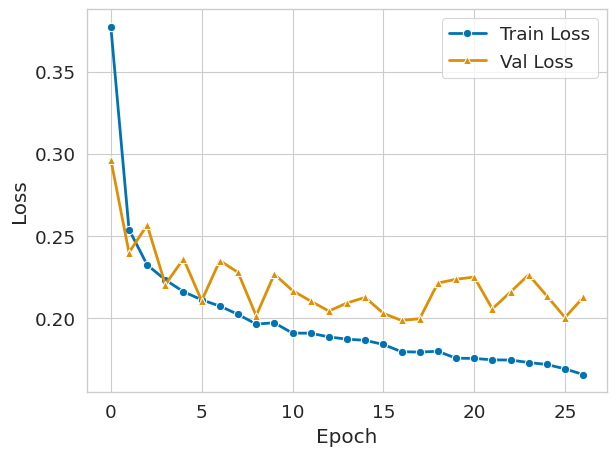

In [ ]:
sns.lineplot(data=df_epoch, x='epoch', y='train/loss', label='Train Loss', marker="o", markersize=6, linewidth=2)
sns.lineplot(data=df_epoch, x='epoch', y='val/loss', label='Val Loss', marker="^", markersize=6, linewidth=2)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.savefig("/content/plots/loss_convergence.pdf")
plt.show()

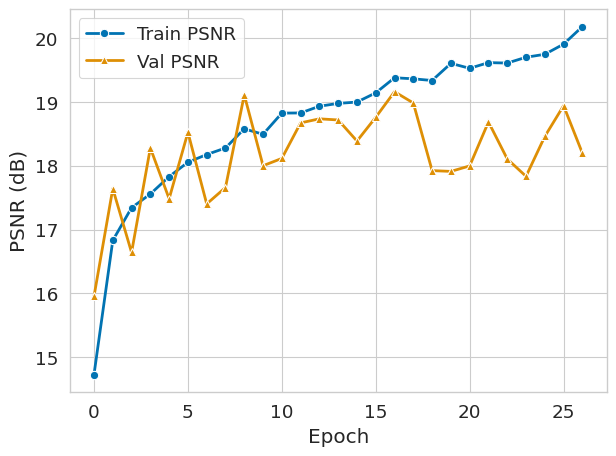

In [ ]:
sns.lineplot(data=df_epoch, x='epoch', y='train/psnr', label='Train PSNR', marker="o", markersize=6, linewidth=2)
sns.lineplot(data=df_epoch, x='epoch', y='val/psnr', label='Val PSNR', marker="^", markersize=6, linewidth=2)

plt.xlabel("Epoch")
plt.ylabel("PSNR (dB)")
plt.legend()
plt.tight_layout()
plt.savefig("/content/plots/psnr.pdf")
plt.show()

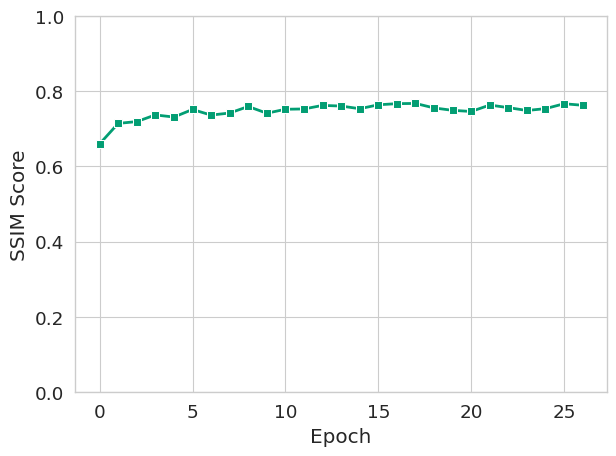

In [ ]:
sns.lineplot(data=df_epoch, x='epoch', y='val/ssim', color=sns.color_palette()[2], marker="s", markersize=6, linewidth=2)

plt.xlabel("Epoch")
plt.ylabel("SSIM Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig("/content/plots/ssim_score.pdf")
plt.show()

In [ ]:
!cp -ru /content/plots "{DRIVE_PATH}"

## Inference

In [40]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if 'best_model' not in locals():
    best_model = LumenNet.load_from_checkpoint(final_ckpt_path).to(device)

best_model = best_model.to(device)

In [41]:
def enhance_full_resolution(model: LumenNet, image_path: str, device: torch.device) -> Image.Image:
    model.eval()
    img    = Image.open(image_path).convert("RGB")
    W, H   = img.size

    tensor = TF.to_tensor(img).unsqueeze(0).to(device)

    pad_h  = (32 - H % 32) % 32
    pad_w  = (32 - W % 32) % 32
    tensor = F.pad(tensor, (0, pad_w, 0, pad_h), mode="reflect")

    with torch.no_grad():
        enhanced = model(tensor)

    enhanced = enhanced[:, :, :H, :W]
    enhanced = enhanced.squeeze(0).clamp(0, 1).cpu()
    return TF.to_pil_image(enhanced)

In [42]:
eval_files = os.listdir(EVAL_LOW_DIR)
# example_file = np.random.choice(eval_files)
example_file = "22.png"

low_path = os.path.join(EVAL_LOW_DIR, example_file)
high_path = os.path.join(EVAL_HIGH_DIR, example_file)

img_low = Image.open(low_path).convert("RGB")
img_high = Image.open(high_path).convert("RGB")
img_pred = enhance_full_resolution(best_model, low_path, device)

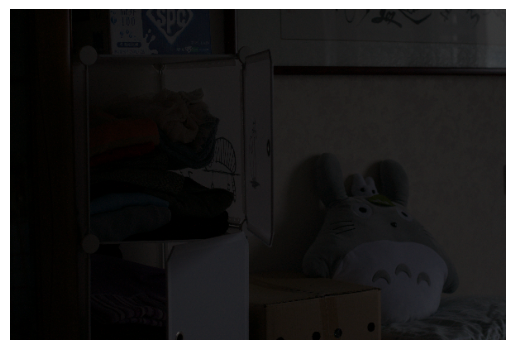

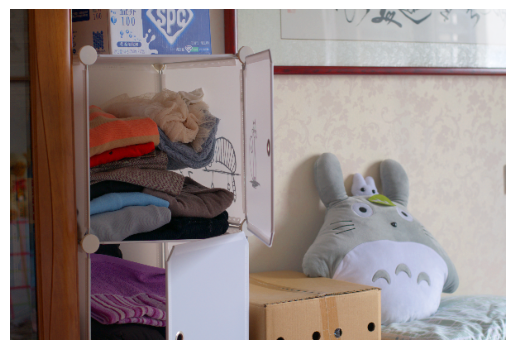

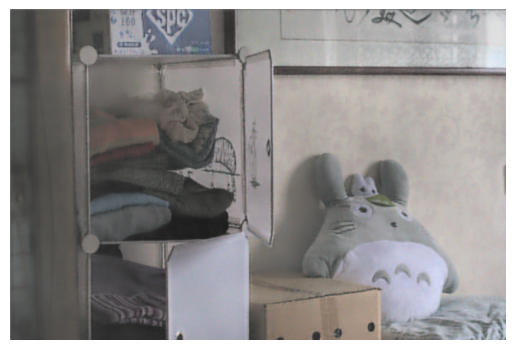

In [44]:
plt.imshow(img_low)
plt.axis('off')
img_low.save(f"/content/plots/low_light_input_{example_file}.png")
plt.show()

plt.imshow(img_high)
plt.axis('off')
img_high.save(f"/content/plots/gt_target_{example_file}.png")
plt.show()

plt.imshow(img_pred)
plt.axis('off')
img_pred.save(f"/content/plots/model_prediction_{example_file}.png")
plt.show()

In [ ]:
!cp -ru /content/plots "{DRIVE_PATH}"

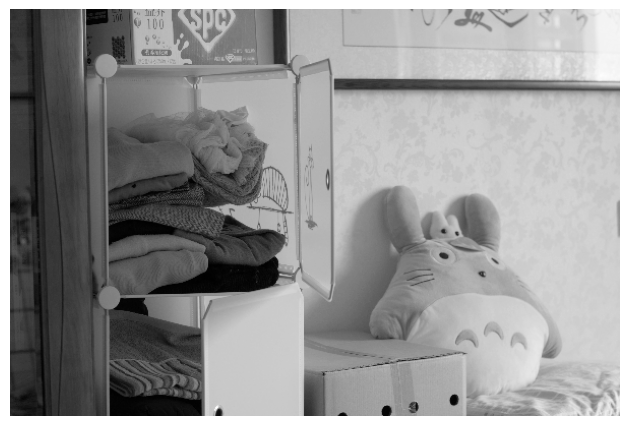

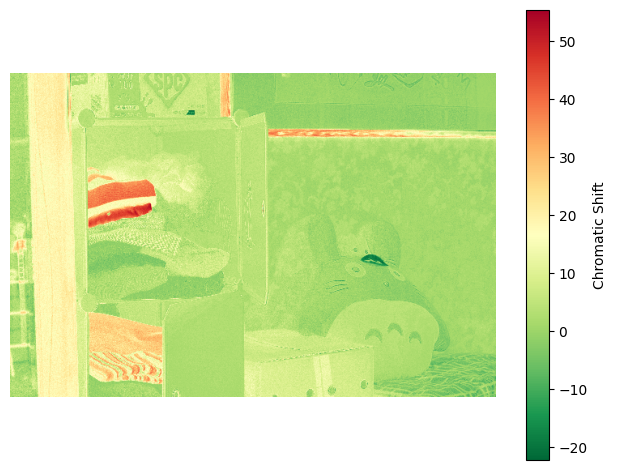

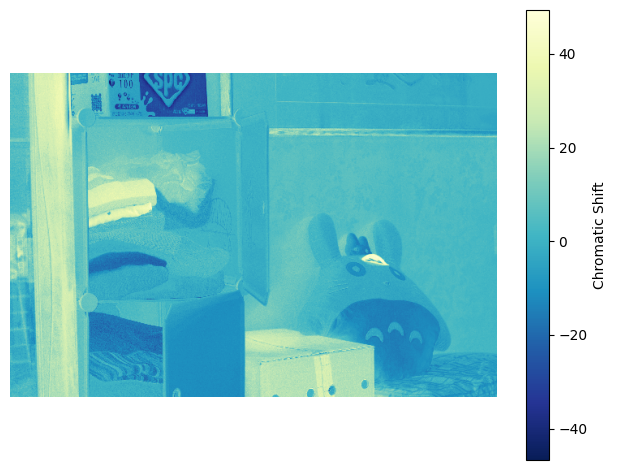

In [ ]:
# the ground truth image
img_tensor = TF.to_tensor(img_high).unsqueeze(0)  # [1, 3, H, W]

# convert to LAB and extract L channel
img_lab = kornia.color.rgb_to_lab(img_tensor)
l_channel = img_lab[0, 0].cpu().numpy()

plt.imshow(l_channel, cmap='gray')
plt.axis('off')
plt.tight_layout()
plt.savefig("/content/plots/l_channel.pdf")
plt.show()

# extract A channel
a_channel = img_lab[0, 1].cpu().numpy()
plt.imshow(a_channel, cmap='RdYlGn_r')
plt.colorbar(label="Chromatic Shift")
plt.axis('off')
plt.tight_layout()
plt.savefig("/content/plots/a_channel.pdf")
plt.show()

# extract B channel
b_channel = img_lab[0, 2].cpu().numpy()
plt.imshow(b_channel, cmap='YlGnBu_r')
plt.colorbar(label="Chromatic Shift")
plt.axis('off')
plt.tight_layout()
plt.savefig("/content/plots/b_channel.pdf")
plt.show()

In [25]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if 'final_ckpt_path' not in locals():
  final_ckpt_path = "/content/checkpoints/lumennet-epoch=16-psnrval/psnr=19.16.ckpt"

if 'best_model' not in locals():
    best_model = LumenNet.load_from_checkpoint(final_ckpt_path).to(device)

best_model = best_model.to(device)

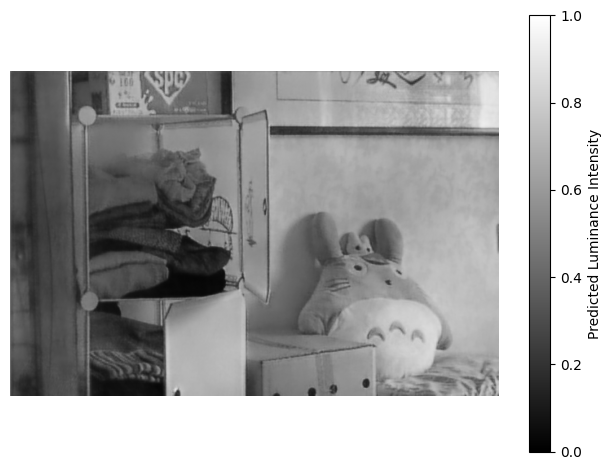

In [ ]:
W, H = img_low.size

# convert to tensor and apply the padding
tensor_low = TF.to_tensor(img_low).unsqueeze(0).to(device)
pad_h  = (32 - H % 32) % 32
pad_w  = (32 - W % 32) % 32
tensor_pad = F.pad(tensor_low, (0, pad_w, 0, pad_h), mode="reflect")

# replicate the pre-processing steps from LumenNet.forward
with torch.no_grad():
    lab = kornia.color.rgb_to_lab(tensor_pad)
    l_chan = lab[:, 0:1, :, :]
    l_norm = l_chan / 100.0

    l_3 = l_norm.repeat(1, 3, 1, 1)

    mean = torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1)
    std = torch.tensor(IMAGENET_STD, device=device).view(1, 3, 1, 1)
    l_3_in = (l_3 - mean) / std

    # intercept the raw U-Net prediction (Shape: [1, 1, H_pad, W_pad])
    raw_unet_output = best_model.model(l_3_in)

# crop away the padding
raw_unet_cropped = raw_unet_output[:, :, :H, :W]

# squeeze to 2D array [H, W] and move to CPU
raw_map = raw_unet_cropped.squeeze().cpu().numpy()

plt.imshow(raw_map, cmap='gray', vmin=0.0, vmax=1.0)
plt.colorbar(label="Predicted Luminance Intensity")
plt.axis('off')
plt.tight_layout()
plt.savefig("/content/plots/pred_luminance_intencit.pdf")
plt.show()